# Tutorial 1: Getting Started

This tutorial introduces the `Mesh` class of PhysicsNeMo-Mesh, which stores point
clouds, curves, surfaces, and volumes as PyTorch tensors.

**What You Will Build:** a mesh made from two tensors, with fields that you
attach, draw, move to a GPU, and differentiate.

You will learn:

- What a `Mesh` holds, and what its manifold and spatial dimensions mean
- How to load meshes and attach data of any rank, with nested keys
- How to draw a mesh, move it to a GPU, and differentiate through its geometry

Prerequisites: Python and PyTorch. The notebook runs on a CPU and uses a GPU when
one is present.

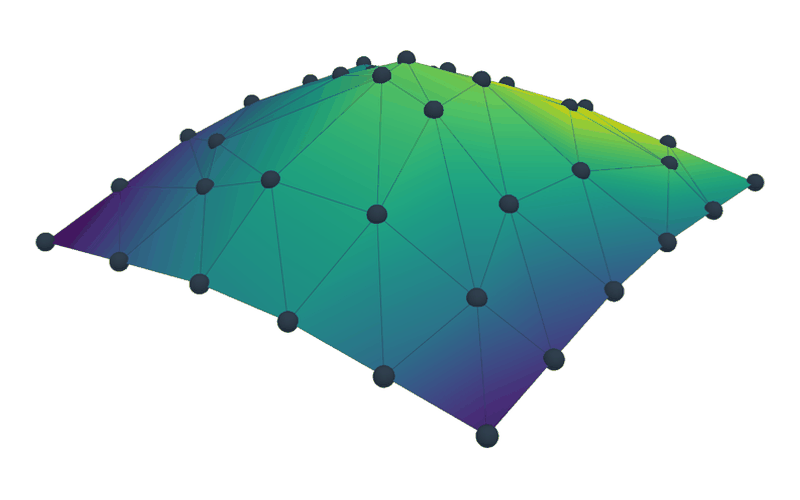

In [1]:
from IPython.display import Image

Image(filename="../../../docs/img/mesh/thumbnails/getting_started.png", width=400)

In [2]:
import matplotlib.pyplot as plt
import pyvista as pv
import torch

from physicsnemo.mesh import Mesh
from physicsnemo.mesh.io import from_pyvista
from physicsnemo.mesh.primitives.curves import circle_3d
from physicsnemo.mesh.primitives.planar import unit_square
from physicsnemo.mesh.primitives.surfaces import sphere_icosahedral
from physicsnemo.mesh.primitives.volumes import cube_volume

# Render PyVista figures as static images, at a modest size.
pv.set_jupyter_backend("static")
pv.global_theme.window_size = [700, 450]

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print(f"device: {device}")

device: cuda


## 1. Create a Mesh from Two Tensors

Simulation meshes from computational fluid dynamics (CFD) and finite element
method (FEM) solvers come as vertex coordinates plus connectivity. A `Mesh`
stores them as two PyTorch tensors, `points` and `cells`, plus three containers
for the data that lives on the mesh. The figure shows a five-point mesh and the
tensors that store it:

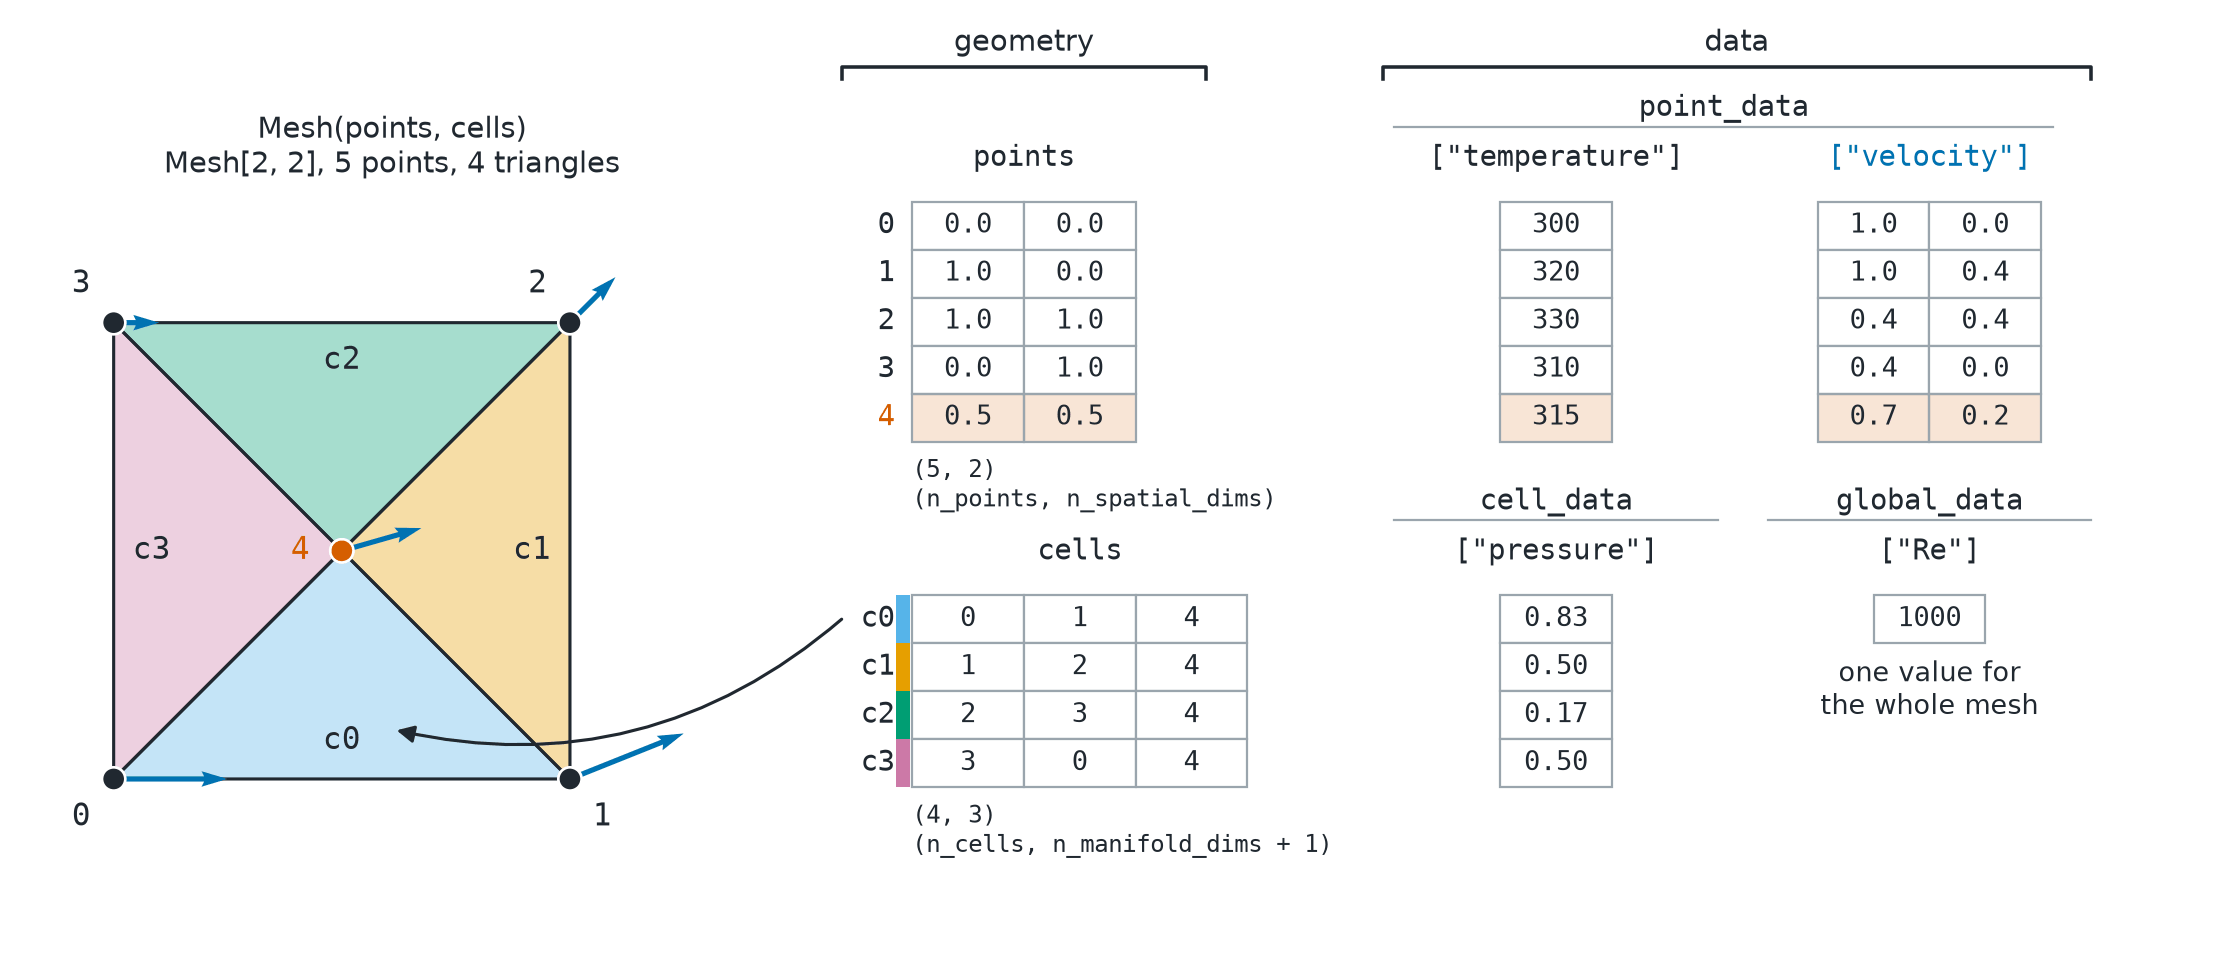

In [3]:
Image(filename="../../../docs/img/mesh/mesh_data_model.png", width=800)

Every cell is a simplex: a point, an edge, a triangle, a tetrahedron, or a
higher-dimensional analog. A simplex of dimension n has n + 1 vertices, so
`cells` has one column more than the manifold dimension. All cells of one mesh
have the same dimension. Tutorial 2 shows how to import quads, polygons, and
other cell types by splitting them into simplices.

Here are two triangles that form a unit square in the plane:

Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=4, n_cells=2)


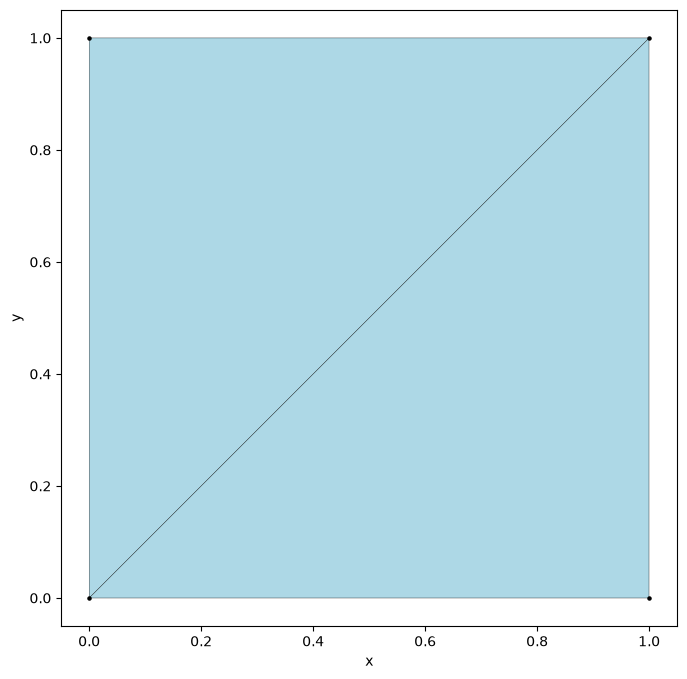

In [4]:
points = torch.tensor(
    [
        [0.0, 0.0],  # vertex 0: bottom left
        [1.0, 0.0],  # vertex 1: bottom right
        [1.0, 1.0],  # vertex 2: top right
        [0.0, 1.0],  # vertex 3: top left
    ]
)
cells = torch.tensor(
    [
        [0, 1, 2],  # triangle 0
        [0, 2, 3],  # triangle 1
    ]
)

mesh = Mesh(points=points, cells=cells)
print(mesh)
_ = mesh.draw()

The printed summary gives the two dimensions and the counts, and `draw()`
(Section 5) plots the mesh. Once the data containers hold fields, the summary
lists them too, as Section 4 shows. The counts and dimensions are also
properties:

In [5]:
print(f"n_points: {mesh.n_points}, n_cells: {mesh.n_cells}")
print(f"n_spatial_dims: {mesh.n_spatial_dims}")
print(f"n_manifold_dims: {mesh.n_manifold_dims}")
print(f"codimension: {mesh.codimension}")

n_points: 4, n_cells: 2
n_spatial_dims: 2
n_manifold_dims: 2
codimension: 0


Geometric quantities are properties too, computed on first access and cached.
Do not assign to `mesh.points`, because the cached values then go out of date.
Section 7 shows how to replace the points safely.

In [6]:
print(f"cell areas: {mesh.cell_areas.tolist()}")
print(f"cell centroids:\n{mesh.cell_centroids}")

cell areas: [0.5, 0.5]
cell centroids:
tensor([[0.6667, 0.3333],
        [0.3333, 0.6667]])


## 2. Mesh Dimensions

One `Mesh` class covers point clouds, curves, surfaces, and volumes. Two numbers
describe which kind a mesh is, and their difference tells you which geometric
operations make sense:

| Term | Meaning | Example |
|------|---------|---------|
| Manifold dimension | The dimension of each cell | 2 for triangles |
| Spatial dimension | The number of coordinates of each point | 3 for a car surface |
| Codimension | Spatial dimension minus manifold dimension | 1 for a surface in 3D |

The figure shows one example mesh for each pair of dimensions, titled with its
type `Mesh[n_manifold_dims, n_spatial_dims]`:

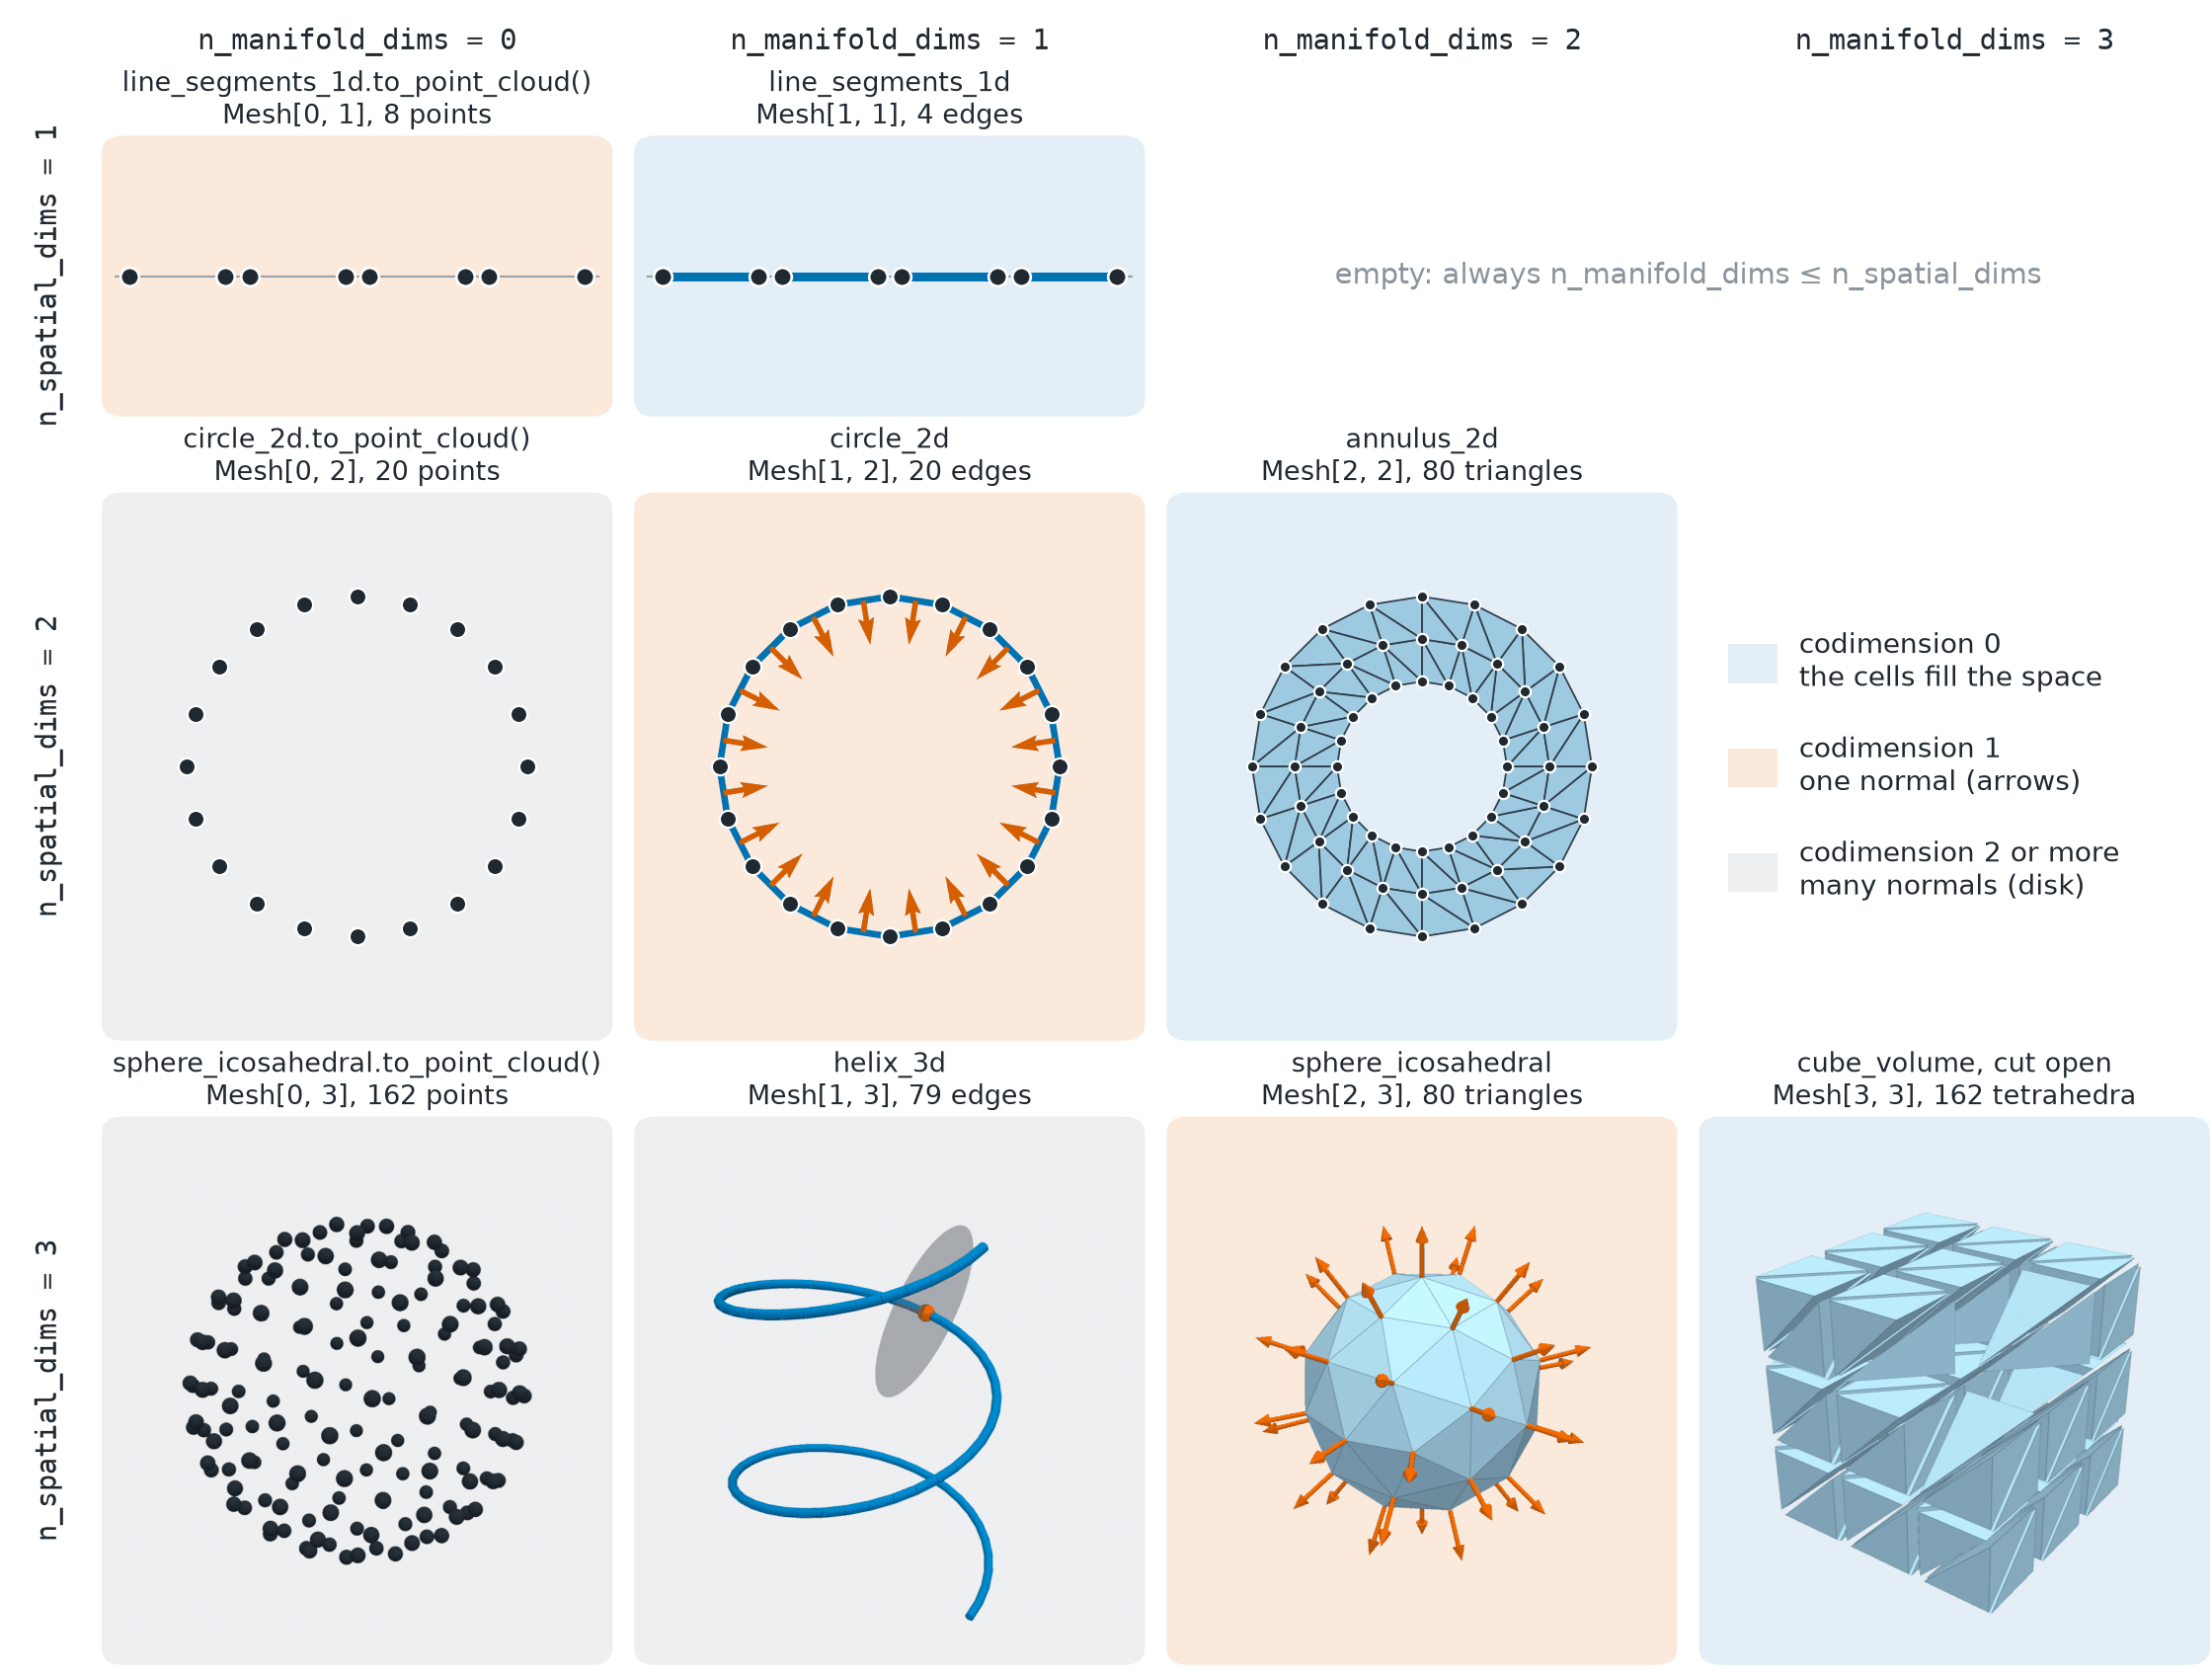

In [7]:
Image(filename="../../../docs/img/mesh/mesh_dimensions.png", width=800)

At codimension 0 (blue), the cells fill the space and have no normal direction.
At codimension 1 (orange), each cell has one normal direction, up to sign. At
codimension 2 or more (gray), a cell has many normal directions.

The meshes in the figure come from `physicsnemo.mesh.primitives`, which
Tutorial 3 tours. The cell below loads four primitives and prints their
dimensions:

In [8]:
examples = {
    "circle_3d (curve in 3D)": circle_3d.load(n_points=32),
    "unit_square (planar triangles)": unit_square.load(subdivisions=5),
    "sphere_icosahedral (surface in 3D)": sphere_icosahedral.load(subdivisions=2),
    "cube_volume (tetrahedra)": cube_volume.load(subdivisions=3),
}
for name, m in examples.items():
    print(
        f"{name:36s} manifold={m.n_manifold_dims}  spatial={m.n_spatial_dims}  "
        f"codimension={m.codimension}"
    )

circle_3d (curve in 3D)              manifold=1  spatial=3  codimension=2
unit_square (planar triangles)       manifold=2  spatial=2  codimension=0
sphere_icosahedral (surface in 3D)   manifold=2  spatial=3  codimension=1
cube_volume (tetrahedra)             manifold=3  spatial=3  codimension=0


Two special cases need no new class. A mesh without `cells` is a point cloud
(manifold dimension 0), and a mesh whose cells are edges is a graph, which
Tutorial 6 uses for graph networks.

The type `Mesh[n_manifold_dims, n_spatial_dims]` names a mesh of given
dimensions. Use it in type hints and in `isinstance` checks, with `...` for "any":

In [9]:
cloud = Mesh(points=torch.randn(100, 3))
print(cloud)

sphere = examples["sphere_icosahedral (surface in 3D)"]
print(f"sphere is a Mesh[2, 3]:   {isinstance(sphere, Mesh[2, 3])}")
print(f"sphere is a Mesh[2, ...]: {isinstance(sphere, Mesh[2, ...])}")
print(f"sphere is a Mesh[3, 3]:   {isinstance(sphere, Mesh[3, 3])}")

Mesh[n_manifold_dims=0, n_spatial_dims=3](n_points=100, n_cells=0)
sphere is a Mesh[2, 3]:   True
sphere is a Mesh[2, ...]: True
sphere is a Mesh[3, 3]:   False


## 3. Load Existing Meshes

Most meshes come from files or from other tools. PyVista reads common formats
such as VTK, STL, OBJ, and PLY, and `from_pyvista` converts a PyVista mesh to a
`Mesh`. The airplane below ships with PyVista, so it needs no download.

In [10]:
airplane = from_pyvista(pv.examples.load_airplane())
print(airplane)

Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=1335, n_cells=2452)


The tutorials folder also has a coarse Stanford bunny, saved with `torch.save`.
`torch.load(..., weights_only=False)` unpickles it. Unpickling can run arbitrary
code, so load only files that you trust. Tutorial 2 shows the native format of
`Mesh.save` and `Mesh.load`, which does not use pickle.

`subdivide` splits each triangle into four. With `"loop"` subdivision, it also
smooths the surface.

In [11]:
bunny = torch.load("assets/bunny.pt", weights_only=False)
print(f"coarse:  {bunny}")

bunny = bunny.subdivide(levels=2, filter="loop")
print(f"refined: {bunny}")

coarse:  Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=400, n_cells=792)
refined: Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=6358, n_cells=12672)


## 4. Attach Data to a Mesh

Simulation results live on the mesh: a temperature at each node, a stress in each
element, a Reynolds number for the whole case. A `Mesh` keeps them in three
containers, one for each level:

| Container | One Entry per | Leading Shape | Example |
|-----------|---------------|---------------|---------|
| `point_data` | Vertex | `(n_points, ...)` | Temperature at each node |
| `cell_data` | Cell | `(n_cells, ...)` | Pressure in each element |
| `global_data` | Mesh | `(...)` | Reynolds number, time step |

Each container is a [TensorDict](https://github.com/pytorch/tensordict): a
dictionary of tensors that share leading dimensions. It moves to a device, slices,
and saves together with the geometry.

You can pass data to the constructor as plain dictionaries:

In [12]:
square = Mesh(
    points=points,
    cells=cells,
    point_data={"temperature": torch.tensor([300.0, 350.0, 340.0, 310.0])},
    cell_data={"pressure": torch.tensor([101.3, 99.8])},
    global_data={"reynolds_number": torch.tensor(1.0e6)},
)
print(square)

Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=4, n_cells=2)
    point_data : {temperature: ()}
    cell_data  : {pressure: ()}
    global_data: {reynolds_number: ()}


### Fields of Any Rank

After the leading dimension, a field can have any shape: nothing for a scalar,
`(3,)` for a vector in 3D, or `(3, 3)` for a rank-2 tensor. You can also
assign fields to an existing mesh, like dictionary entries. The summary lists
the trailing shape of each field.

The temperature below grows with height, and the velocity is a rotation about the
z axis, so that the plots in Section 5 have a clear pattern.

In [13]:
sphere = sphere_icosahedral.load(subdivisions=3)
x, y, z = sphere.points.unbind(dim=-1)

sphere.point_data["temperature"] = 300.0 + 20.0 * z  # rank 0
sphere.point_data["velocity"] = torch.stack(
    [-y, x, torch.zeros_like(z)], dim=-1
)  # rank 1
sphere.cell_data["stress"] = torch.randn(sphere.n_cells, 3, 3)  # rank 2
sphere.cell_data["elasticity"] = torch.randn(sphere.n_cells, 3, 3, 3, 3)  # rank 4
print(sphere)

Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=642, n_cells=1280)
    point_data: {temperature: (), velocity: (3,)}
    cell_data : {elasticity: (3, 3, 3, 3), stress: (3, 3)}


The leading dimension must match the level. A per-point field with the wrong
number of rows raises an error, so every field always matches the geometry:

In [14]:
try:
    sphere.point_data["bad"] = torch.rand(sphere.n_points + 1)
except RuntimeError as error:
    print(f"RuntimeError: {error}")

RuntimeError: batch dimension mismatch, got self.batch_size=torch.Size([642]) and value.shape=torch.Size([643]) for key 'bad'. The leading dimensions of a value must match the batch size.


### Nested Keys

A tuple key creates a nested group, which keeps related fields together, for
example the outputs of one solver or the parameters of one boundary condition.
Read a nested field with the same tuple key.

In [15]:
sphere.point_data["flow", "pressure"] = torch.rand(sphere.n_points)
sphere.point_data["flow", "vorticity"] = torch.randn(sphere.n_points, 3)

sphere.global_data["reynolds_number"] = torch.tensor(1.0e6)
sphere.global_data["inlet", "velocity"] = torch.tensor([1.0, 0.0, 0.0])
sphere.global_data["inlet", "temperature"] = torch.tensor(293.0)
print(sphere)

Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=642, n_cells=1280)
    point_data : {
        flow       : {pressure: (), vorticity: (3,)},
        temperature: (),
        velocity   : (3,)}
    cell_data  : {elasticity: (3, 3, 3, 3), stress: (3, 3)}
    global_data: {
        inlet          : {temperature: (), velocity: (3,)},
        reynolds_number: ()}


In [16]:
print(f"flow pressure shape: {tuple(sphere.point_data['flow', 'pressure'].shape)}")
print(f"inlet velocity:      {sphere.global_data['inlet', 'velocity'].tolist()}")
print("all point fields:")
for key in sphere.point_data.keys(include_nested=True, leaves_only=True):
    print(f"  {key}")

flow pressure shape: (642,)
inlet velocity:      [1.0, 0.0, 0.0]
all point fields:
  temperature
  velocity
  ('flow', 'pressure')
  ('flow', 'vorticity')


### Data and Geometric Transformations

The data containers do not know what their fields mean. When you rotate or scale
a mesh (Tutorial 4), only `points` changes by default. That suits a temperature,
but a velocity must rotate with the geometry. Pass a dictionary to
`transform_point_data` (or `transform_cell_data`, `transform_global_data`) to
select the fields to transform. `True` selects every field, and raises a
`ValueError` for a field whose trailing sizes are not all `n_spatial_dims`.

For a picture of how a scalar, a vector, and a rank-2 tensor change under a
rotation, refer to the figure on the
[Fields and Schemas](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/fields.html)
API page. The cell below rotates the velocity and leaves the temperature alone:

In [17]:
rotated = sphere.rotate(torch.pi / 2, axis="z", transform_point_data={"velocity": True})
print(f"velocity before: {sphere.point_data['velocity'][0].tolist()}")
print(f"velocity after:  {rotated.point_data['velocity'][0].tolist()}")
unchanged = torch.equal(
    sphere.point_data["temperature"], rotated.point_data["temperature"]
)
print(f"temperature unchanged: {unchanged}")

velocity before: [-0.8506508469581604, -0.5257311463356018, 0.0]
velocity after:  [0.5257312059402466, -0.8506508469581604, 0.0]
temperature unchanged: True


The shape of a field does not say everything about it. A `(3, 3)` tensor can be
symmetric or not, and a vector can be a pseudovector, which flips sign under a
reflection. Models that need this information declare it with a `FieldSchema`
from `physicsnemo.mesh.fields`. Tutorial 9 shows how.

## 5. Draw a Mesh

A quick picture catches most mistakes in a mesh or a field. `mesh.draw()` picks a
backend from the spatial dimension: matplotlib for meshes in 1D or 2D, and
PyVista for meshes in 3D. Pass `backend="matplotlib"` or `backend="pyvista"` to
choose one. When you run PyVista outside a notebook, it opens an interactive
window. The first code cell sets this notebook to render static images instead.

A planar mesh draws with matplotlib:

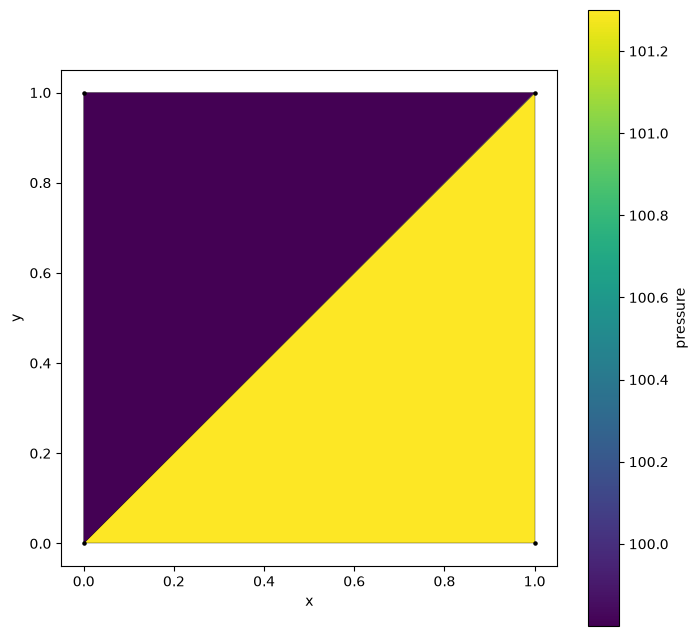

In [18]:
_ = square.draw(cell_scalars="pressure", cmap="viridis")

A surface in 3D draws with PyVista. `point_scalars` colors the surface by a
per-point field, and `cell_scalars` by a per-cell field. The temperature grows
from the bottom of the sphere to the top:

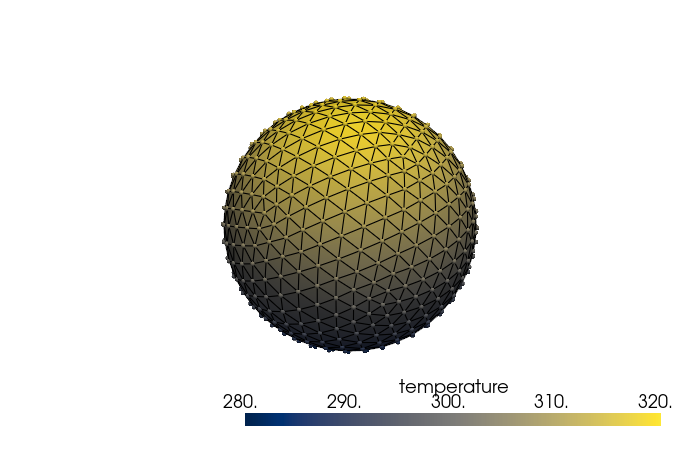

In [19]:
_ = sphere.draw(point_scalars="temperature", cmap="cividis")

`draw` shows a vector or tensor field as its magnitude, the L2 norm over the
trailing dimensions. The speed of the rotation is largest at the equator and zero
at the poles:

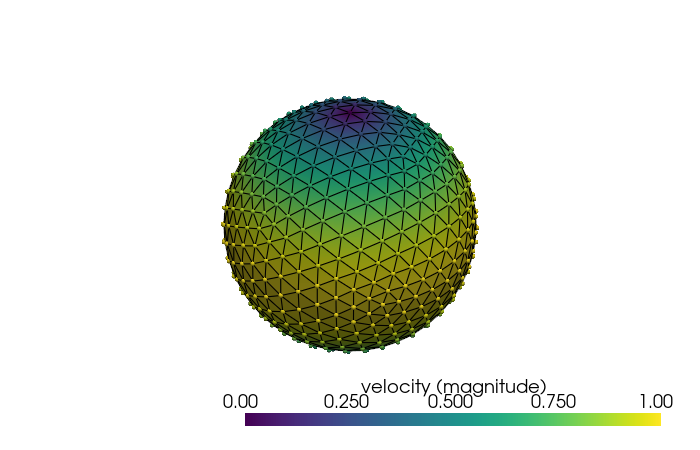

In [20]:
_ = sphere.draw(point_scalars="velocity", cmap="viridis")

Fields can come from the mesh itself. The Gaussian curvature of the bunny's
surface is positive (blue) where the surface bends the same way in every
direction, like a dome. It is negative (red) where the surface is saddle-shaped,
such as at the neck. Tutorial 5 explains curvature.

The values span several orders of magnitude, so the cell compresses them with
`sign(x) * log(1 + |x|)` and clips the color map at the 99th percentile. It also
hides the edges and the vertex dots, which otherwise cover this dense surface.

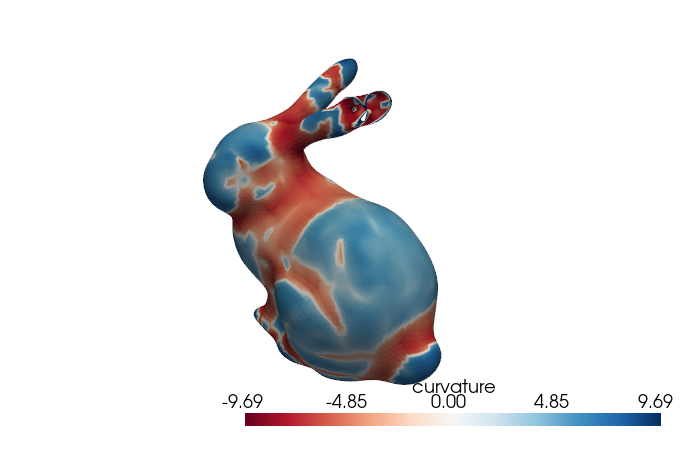

In [21]:
curvature = bunny.gaussian_curvature_vertices
bunny.point_data["curvature"] = curvature.sign() * curvature.abs().log1p()

limit = torch.quantile(bunny.point_data["curvature"].abs(), 0.99).item()
_ = bunny.draw(
    point_scalars="curvature",
    cmap="RdBu",
    vmin=-limit,
    vmax=limit,
    show_edges=False,
    alpha_points=0.0,
)

`draw` returns the matplotlib `Axes` or the PyVista `Plotter`. Pass `show=False`
to customize the figure before you display it:

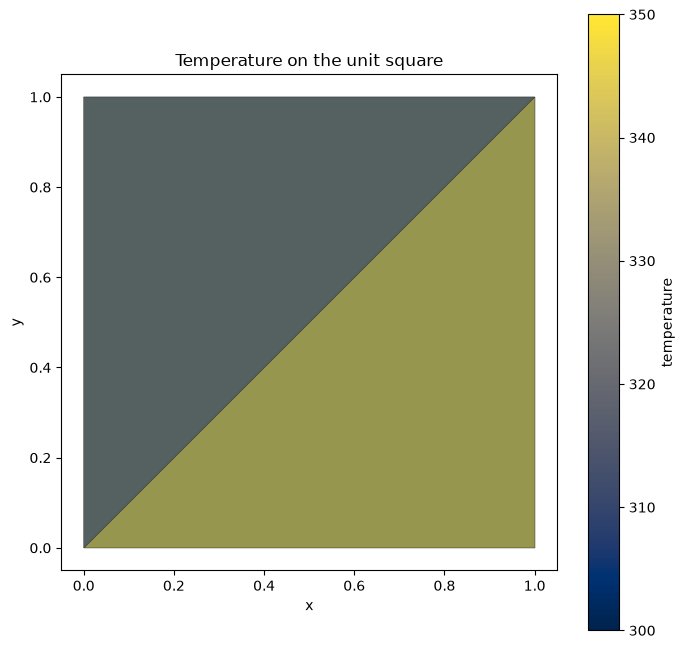

In [22]:
ax = square.draw(show=False, point_scalars="temperature", cmap="cividis")
ax.set_title("Temperature on the unit square")
ax.set_aspect("equal")
plt.show()

## 6. Move a Mesh to a GPU

Most mesh operations are batched PyTorch tensor operations, so they run on a GPU
without code changes. `mesh.to(device)` moves the geometry and every attached
field, nested ones included, in one call.

In [23]:
sphere_on_device = sphere.to(device)
print(f"points:           {sphere_on_device.points.device}")
print(f"temperature:      {sphere_on_device.point_data['temperature'].device}")
print(f"inlet velocity:   {sphere_on_device.global_data['inlet', 'velocity'].device}")

# Computations run where the data is.
gaussian_curvature = sphere_on_device.gaussian_curvature_vertices
print(f"Gaussian curvature computed on: {gaussian_curvature.device}")

points:           cuda:0
temperature:      cuda:0
inlet velocity:   cuda:0


Gaussian curvature computed on: cuda:0


## 7. Differentiate through the Geometry

Most mesh operations are differentiable with PyTorch autograd. That lets you
compute the gradient of an area, a volume, or a model loss with respect to the
vertex positions, as you need for shape optimization and physics-informed
training.

The cell below computes the gradient of a triangle's area with respect to its
vertices:

In [24]:
triangle_points = torch.tensor([[0.0, 0.0], [1.0, 0.0], [0.5, 1.0]], requires_grad=True)
triangle = Mesh(points=triangle_points, cells=torch.tensor([[0, 1, 2]]))

area = triangle.cell_areas.sum()
area.backward()
print(f"area: {area.item():.4f}")
print(f"d(area)/d(points):\n{triangle_points.grad}")

area: 0.5000
d(area)/d(points):
tensor([[-0.5000, -0.2500],
        [ 0.5000, -0.2500],
        [ 0.0000,  0.5000]])


Moving the apex (vertex 2) up grows the area at a rate of 0.5, half the base
length. Moving it sideways does not change the area. The gradient at each base
vertex points away from the opposite edge.

To differentiate through a mesh that you loaded or generated, give it new points
that require gradients. Use `with_points`, which returns a new mesh with the same
cells and data, and no stale cached geometry.

In [25]:
sphere = sphere_icosahedral.load(subdivisions=2)
sphere = sphere.with_points(sphere.points.detach().requires_grad_(True))

total_area = sphere.cell_areas.sum()
total_area.backward()
print(f"surface area: {total_area.item():.4f} (a unit sphere has 4*pi = 12.5664)")
print(f"gradient shape: {tuple(sphere.points.grad.shape)}")

surface area: 12.3291 (a unit sphere has 4*pi = 12.5664)
gradient shape: (162, 3)


Each vertex gradient points outward, because pushing a vertex of a sphere outward
grows its area. The dot product of each gradient with its vertex position is
positive:

In [26]:
outward = (sphere.points.grad * sphere.points.detach()).sum(dim=-1)
print(f"all gradients point outward: {bool((outward > 0).all())}")

all gradients point outward: True


## Summary

This tutorial covered the following points:

- A `Mesh` is two geometry tensors, `points` and `cells`, plus three data
  containers: `point_data`, `cell_data`, and `global_data`.
- Every cell is a simplex. The manifold dimension, the spatial dimension, and
  their difference (the codimension) say what kind of mesh it is.
- `from_pyvista` imports any mesh that PyVista reads.
- Fields can have any rank and can be grouped under nested keys. Their leading
  dimension must match the number of points or cells.
- Geometric transformations change only `points` unless you ask them to transform
  the data too.
- `draw()` plots a mesh, colored by a field. `to(device)` moves the mesh and all of
  its data. Autograd flows through geometric quantities.

## Next Steps

Continue with the following resources:

- **Next:** [Tutorial 2: Loading, Converting, and Saving Meshes](tutorial_2_io_interop.ipynb)
  converts PyVista and VTK meshes, triangulates raw polygons, and saves meshes to
  `.pmsh` and Zarr.
- API Reference: [the `Mesh` class](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/core.html)
  and [fields and schemas](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/fields.html).
- User Guide: [PhysicsNeMo-Mesh](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh.html),
  in particular its chapter on [concepts](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/concepts.html).